<a href="https://colab.research.google.com/github/greeshmareddy98/MLA0201-FOML/blob/main/EXP_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd

df = pd.read_csv('/experiment9_regression_100.csv')

print(df.head(10))
print("Total rows:", len(df))

   Study_Hours  Marks
0         1.00   28.3
1         1.09   28.8
2         1.18   29.2
3         1.27   29.6
4         1.36   30.0
5         1.45   30.3
6         1.55   30.6
7         1.64   30.8
8         1.73   31.1
9         1.82   31.3
Total rows: 100


In [6]:
import os

for root, dirs, files in os.walk('/'):
    if 'experiment9_regression_100.csv' in files:
        print(os.path.join(root, 'experiment9_regression_100.csv'))
    dirs[:] = [d for d in dirs if d not in ['proc', 'sys', 'dev']]

/experiment9_regression_100.csv


Linear Regression R2: 0.987
Polynomial Regression R2: 0.995


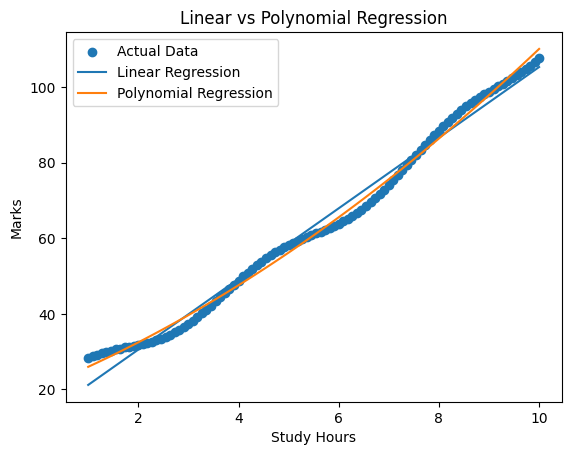

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

# Load dataset
df = pd.read_csv('/experiment9_regression_100.csv')

X = df[['Study_Hours']]
y = df['Marks']

# Linear Regression
linear = LinearRegression()
linear.fit(X, y)
linear_pred = linear.predict(X)

# Polynomial Regression
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly, y)
poly_pred = model.predict(X_poly)

# Display accuracy
print("Linear Regression R2:", round(r2_score(y, linear_pred), 4))
print("Polynomial Regression R2:", round(r2_score(y, poly_pred), 4))

# Plot comparison
plt.scatter(X, y, label='Actual Data')
plt.plot(X, linear_pred, label='Linear Regression')
plt.plot(X, poly_pred, label='Polynomial Regression')
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.title('Linear vs Polynomial Regression')
plt.legend()
plt.show()

In [8]:
# Predict marks for 3 study-hour values
hours = pd.DataFrame({'Study_Hours': [2, 5, 8]})

linear_result = linear.predict(hours)
poly_result = model.predict(poly.transform(hours))

print("Hours | Linear Prediction | Polynomial Prediction")
for i in range(len(hours)):
    print(hours.iloc[i, 0], "|",
          round(linear_result[i], 2), "|",
          round(poly_result[i], 2))

Hours | Linear Prediction | Polynomial Prediction
2 | 30.54 | 32.46
5 | 58.59 | 56.21
8 | 86.64 | 86.41
